# imports

In [2]:
! pip3 install isoplex

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 123.3/123.3 kB 998.2 kB/s eta 0:00:000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 310.7/310.7 kB 2.9 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.7/91.7 kB 7.3 MB/s eta 0:00:00


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
import math
import os
import datetime

sns.set_context('paper')

import math
import warnings
import isoplex
warnings.filterwarnings("ignore")
import sys
sys.path.append('..')  # div.py lives in the repository root
from div import *
from sklearn.preprocessing import MinMaxScaler
sns.set_context('paper')
plt.rcParams.update({
    'font.size': 10 * 0.6,
    'axes.titlesize': 10 * 0.6,
    'axes.labelsize': 10 * 0.6,
    'xtick.labelsize': 10 * 0.6,
    'ytick.labelsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'figure.titlesize': 12 * 0.6,
    'legend.title_fontsize': 10 * 0.6,
    'legend.fontsize': 10 * 0.6,
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'DejaVu Sans']
})

def nnow():
    print(datetime.datetime.now().strftime('%Y-%m-%d  %H:%M:%S'))
nnow()


2026-10-17  14:33:04


In [4]:

def shannon_entropy(np_array, pseudocount=0): # (regular shannon diversity)

    np_array += pseudocount 
    sum_array = sum(np_array)
    
    elements_to_sum = [] 
    for x in np_array:
        if x > 0:
           x = x/sum_array 
           elements_to_sum += [x * math.log(x)]
    
    return -sum(elements_to_sum)

def shannon_evenness(np_array, pseudocount=0): 

    newarray = np_array + pseudocount 
    sum_array = sum(newarray)
    len_array = len(np_array[np_array > 0])
    
    elements_to_sum = [] 
    for x in newarray[newarray > 0]:
           x = x/sum_array 
           elements_to_sum += [x * math.log(x)]
    
    return -sum(elements_to_sum)/math.log(len_array) # for the value to be bound from 0 to 1, we divide the sum by ln(length of array)



''' calculate entropy by perplexity'''
def compute_perplexitys_evenness(arr):
    '''
    The framework captures isoform diversity at two orders: potential (the
    number of observed isoforms, ­ D0) and perplexity (the effective number of isoforms, ­ D1), from which evenness
    ­ (D1/D0) is derived (Fig. 1A). Just as the effective number of species in ecology reflects the species that meaning-
    fully contribute to a community, the effective number of isoforms here reflects those that meaningfully contribute
    to a gene’s transcriptional output.
    https://fairliereese.github.io/isoplex/api/
    https://pubmed.ncbi.nlm.nih.gov/40631152/
    '''
    
    df = isoplex.compute_tpm(pd.Series(arr, name = 'counts').to_frame())
    df = df.assign(gene = 'gene')
    df = isoplex.compute_pi(df, gene_col='gene')
    df = isoplex.compute_entropy(df, gene_col='gene')
    df = isoplex.compute_perplexity(df) # # the effective number of isoforms, ­ D1
    df = isoplex.call_effective(df, gene_col='gene') 
    df = df.reset_index().rename(columns={'index':'transcript'})
    df = isoplex.compute_n_detected_features(df, gene_col='gene', feature_col = 'transcript') 
    df = df.assign(evenness=df['perplexity']/df['n_detected_features'])
    return df.loc[0, 'evenness']



metrices= ['shannon_evenness','shannon_evenness_psdc1','evenness_perplexity', 'DIV_1', 'DIV_10']
colorlist = list(sns.color_palette('winter',3).as_hex()) + list(sns.color_palette('flare_r',2).as_hex())
cp = {m: colorlist[i] for i,m in enumerate(metrices)}

nnow()

outputdir = 'S1_metrics_comparisons/'
if not os.path.isdir(outputdir):
    os.mkdir(outputdir)

2026-10-17  14:33:11


| Metric | Pseudo Count | Dynamic pseudocount % | Numenclature |
| :---: | :---: | :----: | :----: |
| Shannon Evenness | X | X | SE | 
| Shannon Evenness | 1 | X | SE_pdc1 |
| Perplexity Evenness | X | X | Perplexity Evenness |
| DIV | X | 1 | DIV_1 |
| DIV | X | 10 | DIV_10 |

In [7]:
! pip show isoplex

Name: isoplex
Version: 0.1.0
Summary: Compute and filter isoforms or other features based on perplexity
Home-page: 
Author: Fairlie Reese
Author-email: Fairlie Reese <fairlie.reese@gmail.com>
License: MIT
Location: /lustre1/home/martinmikl/sshanas/anaconda3/envs/spl_mpra_map/lib/python3.12/site-packages
Requires: numpy, pandas, typer
Required-by: 


# simple tests of indices

In [263]:
shannon_entropy(np_array=np.array([50,50]), pseudocount=0)

0.6931471805599453

In [264]:
shannon_entropy(np_array=np.array([50,50]), pseudocount=1)

0.6931471805599453

In [265]:
shannon_evenness(np_array=np.array([50,50]), pseudocount=0)

1.0

In [266]:
shannon_evenness(np_array=np.array([50,50]), pseudocount=1)

1.0

In [267]:
DIV(np.array([50,50]), spreading_percentage=1, tpm_or_count='count')

0.9997876633360516

In [268]:
shannon_evenness(np_array=np.array([1,1,0,0,0,0,0,0]), pseudocount=0)

0.33333333333333337

In [130]:
shannon_evenness(np_array=np.array([1,1,0,0,0,0,0,0]), pseudocount=1)

0.9739760316291207

In [71]:
DIV(np.array([1,1,0,0,0,0,0,0]), spreading_percentage=1, tpm_or_count='count')

0.35826926848742596

In [293]:
a = np.array([1,1,0,0,0,0,0,0])
a

array([1, 1, 0, 0, 0, 0, 0, 0])

In [294]:
min(a)

0

In [295]:
min(a[a>0])

1

# sample randomly from distribution

In [2]:
nnow()
def downsample_counts(arr, target_counts):
    """
    Downsample each sample (row) to a target count depth.
    matrix: numpy array (samples x genes)
    """
    # iterate over row             # take row instead of column
    total = arr.sum()
    if total <= target_counts:
        result = arr                # no downsampling needed
    else:
        indices = np.repeat(np.arange(len(arr)), arr.astype(int))
        sampled = np.random.choice(indices, size=target_counts, replace=False)
        result = np.bincount(sampled, minlength=len(arr))
    return result


outputdir = 'S1_metrics_comparisons/'
if not os.path.isdir(outputdir):
    os.mkdir(outputdir)

2026-10-17  14:33:04


2026-10-17  14:35:46


,sum,shannon_evenness,shannon_evenness_psdc1,evenness_perplexity,DIV_1,DIV_10
0,100.0,0.720820,1.038344,0.559597,0.482467,0.575356
1,100.0,0.738121,1.142881,0.625487,0.429342,0.531552
2,100.0,0.695845,1.110260,0.579857,0.406042,0.510427
3,100.0,0.668656,1.039697,0.524786,0.422197,0.523785
4,100.0,0.666102,0.995410,0.499413,0.447361,0.543357
...,...,...,...,...,...,...
11965,19995.0,0.524629,0.527619,0.285209,0.446429,0.542115
11966,19995.0,0.524629,0.527619,0.285209,0.446429,0.542115
11967,19995.0,0.524629,0.527619,0.285209,0.446429,0.542115
11968,19995.0,0.524629,0.527619,0.285209,0.446429,0.542115


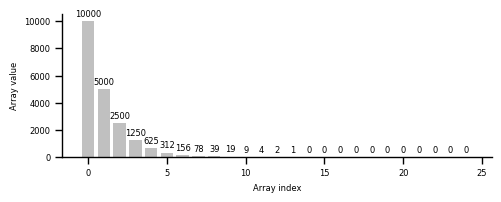

In [5]:
highest_val = 10000
logstep = 2
distribution = np.array([int(highest_val / (logstep**isf)) for isf in range(25)]) # exponential


rp = 30 # repetition of the sampling
n_min, n_max = 100, sum(distribution) # minimum and maximum number sum of downsampled arrays
sim_df = pd.DataFrame(index=range(len(range(n_min, n_max)) * len(range(rp))))
i = 0 # dataframe index
for n in list(range(n_min, n_max, 50)) + [n_max]:
    '''  
    n = sum of downsampled data
    '''
    for _ in range(rp): # repeating the test: because every downsample is slightly different
        a = downsample_counts(arr=distribution, target_counts=n)
        sim_df.loc[i, 'sum'] = n
        sim_df.loc[i,'shannon_evenness'] =  shannon_evenness( a, pseudocount=0)  # shannon evenness (excludes 0s from array when computing)
        sim_df.loc[i,'shannon_evenness_psdc1'] =   shannon_evenness( a, pseudocount=1)  # shannon evenness pseudocount (fills the entire array with pseudocoutn, meaning it include what was once 0s)
        sim_df.loc[i,'evenness_perplexity'] =   compute_perplexitys_evenness(arr=a)
        sim_df.loc[i,'DIV_1'] =   DIV(arr=a, spreading_percentage=1, tpm_or_count='count')
        sim_df.loc[i,'DIV_10'] =   DIV(arr=a, spreading_percentage=10, tpm_or_count='count')
        # sim_df.loc[i,'DIV_100'] =   DIV(arr=a, spreading_percentage=100, tpm_or_count='count')
        i += 1
nnow()
sim_df.dropna(inplace=True)

display(sim_df)    


''' plot underlying disbributions ''' 
fig, ax = plt.subplots(figsize=(5, 2))
bars = ax.bar(range(len(distribution)), distribution, color='silver') # turquoise
ax.bar_label(bars, labels=[f'{height:g}' for height in distribution], padding=2, fontsize=6)
ax.set_xlabel('Array index')
ax.set_ylabel('Array value')
sns.despine()
plt.tight_layout()
fig.savefig(outputdir + 'underlying_distribution.barplot.png', format='png', dpi=300, bbox_inches='tight')

In [6]:
labels_dict = {'shannon_evenness': 'Shannon Evenness', 
               'shannon_evenness_psdc1': 'Shannon Evenness + Pseudocount 1', 
               'evenness_perplexity': 'Perplexity Evenness', 
               'DIV_1': 'I-DIV + Dynamic Peudocount 1%', 
               'DIV_10': 'I-DIV + Dynamic Pseudocount 10%'}

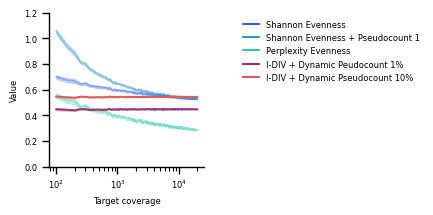

In [8]:



fig, ax = plt.subplots(figsize=(2,2))

sns.lineplot(data = sim_df.melt(value_vars=['shannon_evenness', 'shannon_evenness_psdc1', 'evenness_perplexity'], id_vars=['sum']).sort_values('sum'), 
             x = 'sum', y = 'value', hue = 'variable',alpha = 0.3,
             hue_order=['shannon_evenness', 'shannon_evenness_psdc1','evenness_perplexity'],palette=cp)
sns.lineplot(data = sim_df.melt(value_vars=['DIV_1', 'DIV_10'], id_vars=['sum']).sort_values('sum'), 
             x = 'sum', y = 'value', hue = 'variable',alpha = 1, linewidth = 1.5,
             hue_order=['DIV_1', 'DIV_10'],palette=cp)

ax.set_xscale('log')
plt.ylim(0,1.2)
ax.legend(bbox_to_anchor=(1.2,1), frameon=False)
sns.despine()
ax.set(xlabel = 'Target coverage', ylabel= 'Value')

# Make all line alpha 1 and remove underscores from legend labels
for axis in fig.axes:
    legend = axis.get_legend()
    if legend is not None:
        texts = legend.get_texts()
        for txt in texts:
            txt.set_text(labels_dict[txt.get_text()])

        handles = getattr(legend, 'legendHandles', None)
        if handles is None:
            handles = getattr(legend, 'legend_handles', [])

        for handle in handles:
            try:
                handle.set_alpha(1).get_linewidth(1.1)
            except Exception:
                pass

fig.savefig(outputdir + 'comparisons.lineplot.png', format='png', dpi=300, bbox_inches='tight')